# 10 — The Modifiable Areal Unit Problem (MAUP)

**Question.** How much do the static results depend on the areal units (2,592 census tracts vs 93 UTBs:
the *scale/zoning* effect; Openshaw 1984) and, within one support, on the neighbourhood (queen vs rook vs
KNN-5)?

**What is compared** (everything is computed here; nothing is read from the other notebooks):

1. **Global Moran's I** of the 2022–2025 bulletin count — `esda.Moran`, 999 permutations, every group,
   tracts vs UTBs, three weights.
2. **Gi\* hot / cold spots** — `esda.G_Local(star=True)` on binary weights (`transform="B"`; esda's analytic
   variance is exact only for binary weights), two-sided $p = 2\Phi(-|Z|)$, BH FDR 0.05
   (`statsmodels multipletests`). To compare supports on a common reference (project choice) **each tract takes
   the label of the UTB that covers the largest share of its area** (`geopandas.overlay`, intersection areas).
   Metrics on the 2,592 tracts: raw agreement, Cohen's kappa on the three classes hot / cold / ns
   (`sklearn.metrics.cohen_kappa_score`; Cohen 1960) and the hot-spot Jaccard index
   $|A\cap B|/|A\cup B|$ (`sklearn.metrics.jaccard_score`; Jaccard 1912). Cold-spot Jaccard is NaN when neither
   labelling has a cold spot. Also: the share of all bulletins that fall in hot-spot units on each support
   (the event set is identical on both).
3. **Weights** — the same Gi* labels under queen, rook and KNN-5 on one support, pairwise agreement / kappa /
   hot Jaccard (islands — 2 UTBs under rook — are left out of the comparisons that involve rook).
4. **Scale effect on Spearman's ρ** — `scipy.stats.spearmanr` between bulletins and commercial addresses
   (CNEFE) and between bulletins and population, raw counts and per km², tracts vs UTBs. UTB population is
   interpolated from tracts by area share (`tobler.area_weighted.area_interpolate`, extensive;
   Goodchild & Lam 1980).

Points are a third support in `docs/METHODS.md` §5; they are not compared here (no areal Gi* exists for them).

**Citations.** Openshaw, S. (1984). *The Modifiable Areal Unit Problem*. CATMOG 38. Cohen, J. (1960).
*Educational and Psychological Measurement* 20(1). Jaccard, P. (1912). *New Phytologist* 11(2).
Goodchild, M.F. & Lam, N.S.-N. (1980). *Geo-Processing* 1. Getis & Ord (1992); Ord & Getis (1995);
Moran (1950); Spearman (1904); Benjamini & Hochberg (1995).

In [1]:
import time
import warnings

warnings.filterwarnings("ignore", message=".*island.*")
warnings.filterwarnings("ignore", message=".*not fully connected.*")
warnings.filterwarnings("ignore", category=FutureWarning)
import esda
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from libpysal.weights import KNN, Queen, Rook, W, w_subset
from scipy.stats import norm, spearmanr
from sklearn.metrics import cohen_kappa_score, jaccard_score
from statsmodels.stats.multitest import multipletests
from tobler.area_weighted import area_interpolate

from crime.core.config import NOTEBOOK_OUTPUTS_DIR
from crime.data import GROUPS, load_units, unit_counts, unit_poi_counts

import _mapstyle as ms  # notebooks/_mapstyle.py: basemap, overlay, graticule, scale bar, legends

SEED = 20221
ALPHA = 0.05
PERMUTATIONS = 999
K_NN = 5
SUPPORTS = ("tract", "utb")
WEIGHTS = ("queen", "rook", "knn5")
LAB = {"tract": "census tracts", "utb": "UTBs"}
OUT = NOTEBOOK_OUTPUTS_DIR / "10_maup"
OUT.mkdir(parents=True, exist_ok=True)
T0 = time.time()
ms.setup()
units = {s: load_units(s) for s in SUPPORTS}
counts = {(s, g): unit_counts(s, g).reindex(units[s]["unit_id"]).astype(float) for s in SUPPORTS for g in GROUPS}

In [2]:
def build_w(u, kind):
    if kind == "queen":
        w = Queen.from_dataframe(u, ids="unit_id", use_index=False)
    elif kind == "rook":
        w = Rook.from_dataframe(u, ids="unit_id", use_index=False)
    else:
        cent = gpd.GeoDataFrame({"unit_id": u["unit_id"].to_numpy()}, geometry=u.geometry.centroid.to_numpy(), crs=u.crs)
        w = KNN.from_dataframe(cent, k=K_NN, ids="unit_id")
    assert list(w.id_order) == list(u["unit_id"])
    isl = list(w.islands)
    if isl:
        w = w_subset(w, [i for i in w.id_order if i not in set(isl)])
    return w, isl

weights = {(s, k): build_w(units[s], k) for s in SUPPORTS for k in WEIGHTS}
for (s, k), (w, isl) in weights.items():
    print(f"{s:5s} {k:5s}: n = {w.n}, islands dropped = {isl}")

def gi_labels(s, g, k):
    w, _ = weights[s, k]
    y = counts[s, g].reindex(w.id_order).to_numpy()
    wb = W(w.neighbors, id_order=w.id_order, silence_warnings=True)
    gi = esda.G_Local(y, wb, transform="B", star=True, permutations=0)
    z = np.asarray(gi.Zs)
    q = multipletests(2 * norm.sf(np.abs(z)), alpha=ALPHA, method="fdr_bh")[1]
    return pd.Series(np.where(q <= ALPHA, np.where(z > 0, "hot", "cold"), "ns"), index=w.id_order)

gi = {(s, g, k): gi_labels(s, g, k) for s in SUPPORTS for g in GROUPS for k in WEIGHTS}

tract queen: n = 2592, islands dropped = []
tract rook : n = 2592, islands dropped = []
tract knn5 : n = 2592, islands dropped = []
utb   queen: n = 93, islands dropped = []
utb   rook : n = 91, islands dropped = ['UTR - Campo Grande 3', 'UTR - Campo Grande 4']
utb   knn5 : n = 93, islands dropped = []


## 1. Global Moran's I: tracts vs UTBs

In [3]:
rows = []
for s in SUPPORTS:
    for g in GROUPS:
        for k in WEIGHTS:
            w, _ = weights[s, k]
            w = W(w.neighbors, id_order=w.id_order, silence_warnings=True); w.transform = "r"
            np.random.seed(SEED)
            mi = esda.Moran(counts[s, g].reindex(w.id_order).to_numpy(), w, permutations=PERMUTATIONS)
            rows.append(dict(support=s, group=g, weights=k, I=mi.I, p_sim=mi.p_sim, z_norm=mi.z_norm))
moran = pd.DataFrame(rows)
moran.to_csv(OUT / "moran_by_support_weights.csv", index=False)
mw = moran.pivot_table(index="group", columns=["weights", "support"], values="I").reindex(list(GROUPS))
mw.round(3)

weights       knn5         queen          rook       
support      tract    utb  tract    utb  tract    utb
group                                                
all          0.298  0.390  0.376  0.339  0.391  0.363
property     0.316  0.390  0.398  0.339  0.413  0.363
bodily_harm  0.094  0.399  0.130  0.335  0.141  0.367
traffic      0.042  0.450  0.115  0.425  0.115  0.449
drug         0.149  0.117  0.183  0.097  0.193  0.114
violent      0.083  0.164  0.112  0.123  0.111  0.165

## 2. Gi* hot spots: tracts vs UTBs on the tract reference (queen)

In [4]:
tr, ut = units["tract"], units["utb"]
ov = gpd.overlay(tr[["unit_id", "geometry"]].rename(columns={"unit_id": "tract"}),
                 ut[["unit_id", "geometry"]].rename(columns={"unit_id": "utb"}), how="intersection", keep_geom_type=True)
ov["a"] = ov.area
best = ov.sort_values("a").groupby("tract").tail(1).set_index("tract")
share = (best["a"] / ov.groupby("tract")["a"].sum()).reindex(tr["unit_id"])
tract2utb = best["utb"].reindex(tr["unit_id"])
missing = tract2utb.isna()
if missing.any():   # tracts in slivers outside every UTB polygon: nearest UTB
    near = gpd.sjoin_nearest(tr.loc[missing.to_numpy(), ["unit_id", "geometry"]], ut[["unit_id", "geometry"]].rename(columns={"unit_id": "utb"}))
    tract2utb.loc[near["unit_id"].to_numpy()] = near["utb"].to_numpy()
print(f"tracts without any UTB overlap: {int(missing.sum())}; "
      f"largest-UTB share of tract area: median {share.median():.3f}, tracts with share < 0.9: {int((share < 0.9).sum())}")
pd.DataFrame({"utb": tract2utb, "area_share": share}).to_csv(OUT / "tract_to_utb.csv")

tracts without any UTB overlap: 0; largest-UTB share of tract area: median 1.000, tracts with share < 0.9: 129


In [5]:
def compare(a, b):
    a, b = np.asarray(a), np.asarray(b)
    out = dict(n=len(a), agreement=(a == b).mean(), kappa=cohen_kappa_score(a, b),
               hot_a=int((a == "hot").sum()), hot_b=int((b == "hot").sum()),
               cold_a=int((a == "cold").sum()), cold_b=int((b == "cold").sum()))
    for c in ("hot", "cold"):
        x, y = a == c, b == c
        out[f"jaccard_{c}"] = jaccard_score(x, y) if (x | y).any() else np.nan
    return out

rows = []
for g in GROUPS:
    t = gi["tract", g, "queen"].reindex(tr["unit_id"])
    u_on_t = tract2utb.map(gi["utb", g, "queen"])
    r = compare(t, u_on_t)
    yt, yu = counts["tract", g], counts["utb", g]
    r.update(group=g, events=int(yt.sum()),
             share_events_in_hot_tracts=yt[t.to_numpy() == "hot"].sum() / yt.sum(),
             share_events_in_hot_utbs=yu.reindex(gi["utb", g, "queen"].index)[gi["utb", g, "queen"].to_numpy() == "hot"].sum() / yu.sum(),
             share_area_hot_tracts=tr["area_km2"][t.to_numpy() == "hot"].sum() / tr["area_km2"].sum(),
             share_area_hot_utbs=ut.set_index("unit_id")["area_km2"].reindex(gi["utb", g, "queen"].index)[gi["utb", g, "queen"].to_numpy() == "hot"].sum() / ut["area_km2"].sum())
    rows.append(r)
sup = pd.DataFrame(rows).rename(columns={"hot_a": "hot_tracts", "hot_b": "tracts_in_hot_utbs", "cold_a": "cold_tracts", "cold_b": "tracts_in_cold_utbs"})
sup = sup[["group", "events", "n", "hot_tracts", "tracts_in_hot_utbs", "cold_tracts", "tracts_in_cold_utbs", "agreement", "kappa",
           "jaccard_hot", "jaccard_cold", "share_events_in_hot_tracts", "share_events_in_hot_utbs", "share_area_hot_tracts", "share_area_hot_utbs"]]
sup.to_csv(OUT / "gi_tract_vs_utb_queen.csv", index=False)
sup.round(3)

,group,events,n,hot_tracts,tracts_in_hot_utbs,cold_tracts,tracts_in_cold_utbs,agreement,kappa,jaccard_hot,jaccard_cold,share_events_in_hot_tracts,share_events_in_hot_utbs,share_area_hot_tracts,share_area_hot_utbs
0,all,107859,2592,149,489,0,0,0.830,0.244,0.184,NaN,0.290,0.398,0.075,0.039
1,property,90436,2592,152,489,0,0,0.832,0.255,0.191,NaN,0.303,0.422,0.062,0.039
2,bodily_harm,6590,2592,146,1067,0,0,0.612,0.080,0.094,NaN,0.184,0.505,0.042,0.122
3,traffic,6302,2592,219,1012,0,0,0.617,0.063,0.107,NaN,0.324,0.493,0.159,0.116
4,drug,4032,2592,58,489,0,0,0.817,0.095,0.070,NaN,0.295,0.292,0.014,0.039
5,violent,499,2592,108,642,0,0,0.738,0.024,0.049,NaN,0.269,0.309,0.111,0.094


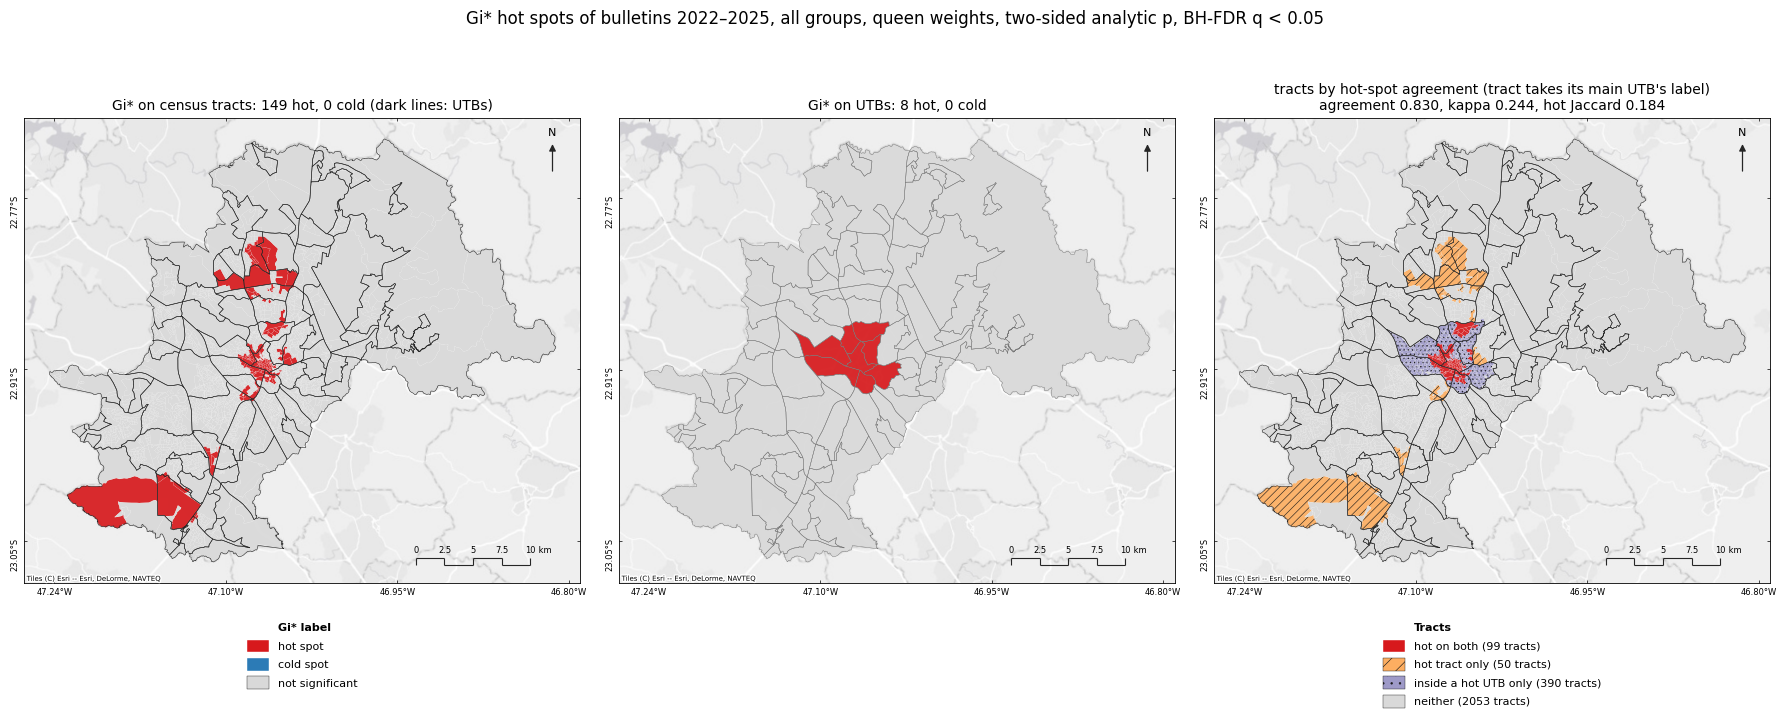

In [6]:
AG = {"hot on both": ("#d7191c", ""), "hot tract only": ("#fdae61", "//"), "inside a hot UTB only": ("#9e9ac8", ".."),
      "neither": ("#d9d9d9", "")}
GI = {"hot": ("#d7191c", ""), "cold": ("#2c7bb6", ""), "ns": ("#d9d9d9", "")}
GI_NAME = {"hot": "hot spot", "cold": "cold spot", "ns": "not significant"}
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
t = gi["tract", "all", "queen"].reindex(tr["unit_id"]).to_numpy()
u_on_t = tract2utb.map(gi["utb", "all", "queen"]).to_numpy()
ms.plot_categories(axes[0], tr, t, GI, linewidth=0.05)
axes[0].set_title(f"Gi* on census tracts: {int((t == 'hot').sum())} hot, {int((t == 'cold').sum())} cold (dark lines: UTBs)", fontsize=10)
ulab = ut["unit_id"].map(gi["utb", "all", "queen"]).to_numpy()
ms.plot_categories(axes[1], ut, ulab, GI, linewidth=0.3, edgecolor="0.45")
axes[1].set_title(f"Gi* on UTBs: {int((ulab == 'hot').sum())} hot, {int((ulab == 'cold').sum())} cold", fontsize=10)
cat = np.select([(t == "hot") & (u_on_t == "hot"), t == "hot", u_on_t == "hot"], list(AG)[:3], "neither")
ms.plot_categories(axes[2], tr, cat, AG, hatch_repeat=2, linewidth=0.05)
r = sup.set_index("group").loc["all"]
axes[2].set_title(f"tracts by hot-spot agreement (tract takes its main UTB's label)\n"
                  f"agreement {r.agreement:.3f}, kappa {r.kappa:.3f}, hot Jaccard {r.jaccard_hot:.3f}", fontsize=10)
for ax, overlay in zip(axes, (ut, None, ut)):
    ms.decorate(ax, tr.crs, overlay=overlay)
vc = pd.Series(cat).value_counts()
ms.category_legend(axes[2], {"Tracts": [(k, *v) for k, v in AG.items()]},
                   counts={k: f"{vc.get(k, 0)} tracts" for k in AG}, bbox=(0.5, -0.06), fontsize=8)
ms.category_legend(axes[0], {"Gi* label": [(GI_NAME[c], *GI[c]) for c in GI]}, bbox=(0.5, -0.06), fontsize=8)
fig.suptitle("Gi* hot spots of bulletins 2022–2025, all groups, queen weights, two-sided analytic p, BH-FDR q < 0.05", fontsize=12)
fig.tight_layout(); fig.savefig(OUT / "gi_tract_vs_utb_all.png", dpi=300, bbox_inches="tight")
plt.show(); plt.close(fig)

## 3. Weights: queen vs rook vs KNN-5 (Gi* labels, BH-FDR)

In [7]:
rows = []
for s in SUPPORTS:
    for g in GROUPS:
        for a, b in (("queen", "rook"), ("queen", "knn5"), ("rook", "knn5")):
            la, lb = gi[s, g, a], gi[s, g, b]
            common = la.index.intersection(lb.index)
            r = compare(la[common], lb[common])
            r.update(support=s, group=g, pair=f"{a} vs {b}")
            rows.append(r)
wag = pd.DataFrame(rows)[["support", "group", "pair", "n", "hot_a", "hot_b", "agreement", "kappa", "jaccard_hot", "jaccard_cold"]]
wag.to_csv(OUT / "gi_weights_agreement.csv", index=False)
wag.pivot_table(index=["support", "group"], columns="pair", values=["kappa", "jaccard_hot"]).reindex(list(GROUPS), level=1).round(3)

jaccard_hot                                    kappa  \
pair                queen vs knn5 queen vs rook rook vs knn5 queen vs knn5   
support group                                                                
tract   all                 0.240         0.865        0.255         0.373   
        property            0.222         0.890        0.239         0.349   
        bodily_harm         0.213         0.836        0.234         0.337   
        traffic             0.064         0.887        0.070         0.111   
        drug                0.292         0.898        0.311         0.445   
        violent             0.248         0.814        0.252         0.382   
utb     all                 0.889         0.889        1.000         0.935   
        property            0.889         0.889        1.000         0.935   
        bodily_harm         0.786         0.846        0.769         0.861   
        traffic             0.786         0.923        0.733         0.861   
        drug                0.889         0.875        0.778         0.935   
        violent             0.100         0.375        0.333         0.166   

                                                
pair                queen vs rook rook vs knn5  
support group                                   
tract   all                 0.923        0.393  
        property            0.939        0.373  
        bodily_harm         0.905        0.365  
        traffic             0.935        0.122  
        drug                0.945        0.468  
        violent             0.893        0.387  
utb     all                 0.935        1.000  
        property            0.935        1.000  
        bodily_harm         0.904        0.851  
        traffic             0.954        0.821  
        drug                0.927        0.863  
        violent             0.523        0.492

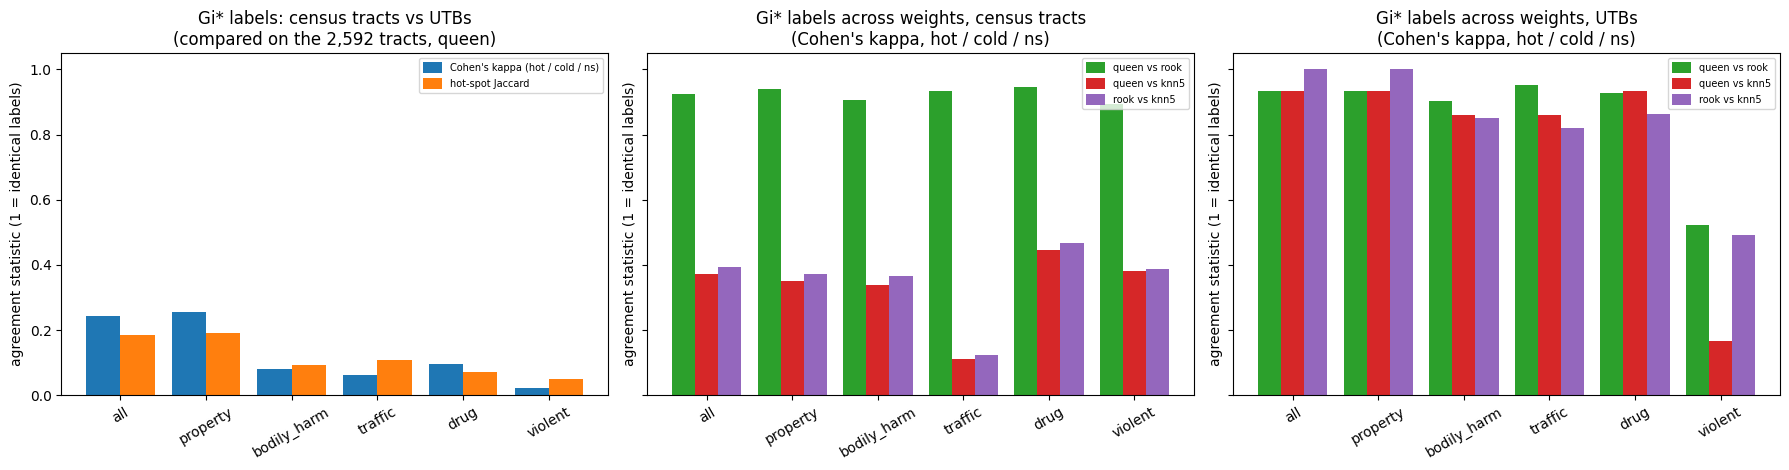

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
x = np.arange(len(GROUPS))
axes[0].bar(x - 0.2, sup["kappa"], width=0.4, label="Cohen's kappa (hot / cold / ns)")
axes[0].bar(x + 0.2, sup["jaccard_hot"], width=0.4, label="hot-spot Jaccard")
axes[0].set_title("Gi* labels: census tracts vs UTBs\n(compared on the 2,592 tracts, queen)")
for ax, s in zip(axes[1:], SUPPORTS):
    for j, pair in enumerate(("queen vs rook", "queen vs knn5", "rook vs knn5")):
        v = wag.query("support == @s and pair == @pair").set_index("group").reindex(list(GROUPS))["kappa"]
        ax.bar(x + (j - 1) * 0.27, v, width=0.27, color=f"C{j + 2}", label=pair)
    ax.set_title(f"Gi* labels across weights, {LAB[s]}\n(Cohen's kappa, hot / cold / ns)")
for ax in axes:
    ax.set_xticks(x, GROUPS, rotation=30); ax.set_ylabel("agreement statistic (1 = identical labels)")
    ax.set_ylim(0, 1.05); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUT / "agreement_bars.png", dpi=300)
plt.show(); plt.close(fig)

## 4. Scale effect on Spearman's ρ

In [9]:
pop_utb = area_interpolate(source_df=tr[["population", "geometry"]], target_df=ut[["unit_id", "geometry"]], extensive_variables=["population"])
feat = {"tract": unit_poi_counts("tract").reindex(tr["unit_id"]).assign(population=tr["population"].to_numpy(), area_km2=tr["area_km2"].to_numpy()),
        "utb": unit_poi_counts("utb").reindex(ut["unit_id"]).assign(population=pop_utb["population"].to_numpy(), area_km2=ut["area_km2"].to_numpy())}
rows = []
for s in SUPPORTS:
    f = feat[s]
    for g in GROUPS:
        y = counts[s, g].reindex(f.index)
        for v in ("n_commercial", "population"):
            for scale in ("count", "per_km2"):
                a = f["area_km2"] if scale == "per_km2" else 1.0
                r = spearmanr(f[v] / a, y / a)
                rows.append(dict(support=s, group=g, feature=v, scale=scale, n=len(y), rho=r.statistic, p=r.pvalue))
rho = pd.DataFrame(rows)
rho.to_csv(OUT / "spearman_scale_effect.csv", index=False)
rw = rho.pivot_table(index="group", columns=["feature", "scale", "support"], values="rho").reindex(list(GROUPS))
rw.round(3)

feature     n_commercial                       population                 \
scale              count        per_km2             count        per_km2   
support            tract    utb   tract    utb      tract    utb   tract   
group                                                                      
all                0.728  0.923   0.593  0.912      0.159  0.902   0.156   
property           0.721  0.918   0.578  0.909      0.146  0.889   0.121   
bodily_harm        0.555  0.933   0.410  0.910      0.209  0.940   0.039   
traffic            0.547  0.893   0.371  0.865      0.057  0.888  -0.218   
drug               0.308  0.871   0.242  0.831      0.121  0.880  -0.042   
violent            0.217  0.777   0.103  0.742      0.096  0.788  -0.129   

feature             
scale               
support        utb  
group               
all          0.888  
property     0.879  
bodily_harm  0.911  
traffic      0.850  
drug         0.845  
violent      0.757

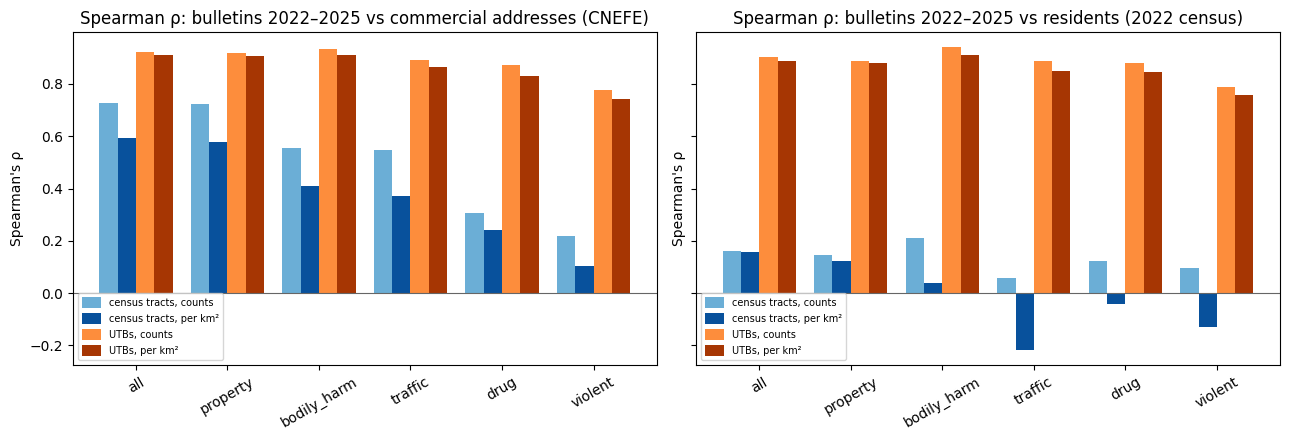

runtime 73 s


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, v in zip(axes, ("n_commercial", "population")):
    for j, (s, scale) in enumerate([("tract", "count"), ("tract", "per_km2"), ("utb", "count"), ("utb", "per_km2")]):
        vals = rho.query("support == @s and feature == @v and scale == @scale").set_index("group").reindex(list(GROUPS))["rho"]
        ax.bar(x + (j - 1.5) * 0.2, vals, width=0.2, label=f"{LAB[s]}, {'counts' if scale == 'count' else 'per km²'}",
               color=["#6baed6", "#08519c", "#fd8d3c", "#a63603"][j])
    ax.axhline(0, color="0.4", lw=0.8)
    ax.set_xticks(x, GROUPS, rotation=30)
    name = "commercial addresses (CNEFE)" if v == "n_commercial" else "residents (2022 census)"
    ax.set_title(f"Spearman ρ: bulletins 2022–2025 vs {name}")
    ax.set_ylabel("Spearman's ρ")
    ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUT / "spearman_scale_effect.png", dpi=300)
plt.show(); plt.close(fig)
print(f"runtime {time.time() - T0:.0f} s")

In [11]:
# numbers quoted in the Findings cell
pd.set_option("display.width", 200)
print(mw.round(3).to_string())
print(sup.round(3).to_string(index=False))
print(wag.round(3).to_string(index=False))
print(rw.round(2).to_string())

weights       knn5         queen          rook       
support      tract    utb  tract    utb  tract    utb
group                                                
all          0.298  0.390  0.376  0.339  0.391  0.363
property     0.316  0.390  0.398  0.339  0.413  0.363
bodily_harm  0.094  0.399  0.130  0.335  0.141  0.367
traffic      0.042  0.450  0.115  0.425  0.115  0.449
drug         0.149  0.117  0.183  0.097  0.193  0.114
violent      0.083  0.164  0.112  0.123  0.111  0.165
      group  events    n  hot_tracts  tracts_in_hot_utbs  cold_tracts  tracts_in_cold_utbs  agreement  kappa  jaccard_hot  jaccard_cold  share_events_in_hot_tracts  share_events_in_hot_utbs  share_area_hot_tracts  share_area_hot_utbs
        all  107859 2592         149                 489            0                    0      0.830  0.244        0.184           NaN                       0.290                     0.398                  0.075                0.039
   property   90436 2592         152          

## Findings

*Numbers from the cells above (seed 20221); CSVs in `outputs/nb/10_maup/`.*

- **Global Moran's I depends on the support, and differently by group.** All groups: 0.376 on tracts vs
  0.339 on UTBs (queen); with KNN-5 the order reverses (0.298 vs 0.390). The sparse groups gain most from
  aggregation: traffic 0.115 → 0.425 and bodily harm 0.130 → 0.335 (queen); drug goes the other way
  (0.183 → 0.097).
- **Tract → UTB reference.** Every tract overlaps a UTB; the median tract lies entirely (share 1.000) in
  its main UTB, and 129 tracts have less than 90 % of their area in it.
- **Gi\* hot spots barely agree across supports.** All groups, queen: 149 hot tracts vs 489 tracts inside the
  8 hot UTBs; agreement 0.830 but **Cohen's kappa 0.244 and hot-spot Jaccard 0.184** (99 tracts hot on both,
  50 hot tracts outside a hot UTB, 390 non-hot tracts inside a hot UTB). The 50 tract-only hot spots include
  very large peripheral tracts in the south. Kappa is 0.02–0.10 for the sparse groups (violent: 0.024,
  Jaccard 0.049). The high raw agreement comes from the many units that are "not significant" on both.
- **Cold spots:** none on either support for any group, so cold Jaccard is NaN throughout and kappa
  measures hot vs rest only.
- **Same events, different "hot" share.** Hot tracts hold 29.0 % of all bulletins on 7.5 % of the
  municipal area; hot UTBs hold 39.8 % on 3.9 %. For bodily harm the hot UTBs hold 50.5 % of the bulletins vs
  18.4 % in hot tracts. How concentrated crime looks depends on the zoning.
- **Weights within a support.** Queen and rook agree closely on tracts (kappa 0.89–0.95, hot Jaccard
  0.81–0.90). **KNN-5 does not** (queen vs KNN-5 kappa 0.11–0.45; traffic 219 → 14 hot tracts): on tracts the
  neighbourhood choice changes the result about as much as the support does. On UTBs all three weights agree
  (kappa 0.82–1.00) except violent (queen vs KNN-5 kappa 0.166; 10 vs 1 hot UTB).
- **Scale effect on Spearman's ρ.** Bulletins vs commercial addresses: ρ = 0.728 on tracts vs 0.923 on UTBs
  (counts), 0.593 vs 0.912 (per km²). Bulletins vs residents: **0.159 on tracts vs 0.902 on UTBs** (counts);
  per km², tracts give 0.156 for all groups and negative values for traffic (−0.218), violent (−0.129) and drug
  (−0.042), whereas UTBs give 0.76–0.91 for every group. Aggregating to 93 large units makes nearly every
  extensive quantity correlate with every other (they all grow with the developed area of the unit, and the
  UTB population is itself area-interpolated), so the UTB correlations say little about tract-level
  association.
- Points (the third support in `docs/METHODS.md` §5) are not compared here.